**IMPORTING LIBRARIES**

---



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

**LOADING DATASET**

---



In [2]:
diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data,columns=diabetes.feature_names)
y = pd.Series(diabetes.target, name="Disease_Progression")

df = X.copy()
df["Disease_Progression"] = y
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


**PREPROCESSING STEPS**

---



In [3]:
df.shape

(442, 11)

In [4]:
X.columns

Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6'], dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  442 non-null    float64
 1   sex                  442 non-null    float64
 2   bmi                  442 non-null    float64
 3   bp                   442 non-null    float64
 4   s1                   442 non-null    float64
 5   s2                   442 non-null    float64
 6   s3                   442 non-null    float64
 7   s4                   442 non-null    float64
 8   s5                   442 non-null    float64
 9   s6                   442 non-null    float64
 10  Disease_Progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [6]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Disease_Progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


**CHECKING MISSING VALUES**

---



In [7]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Since there are no missing values in the dataset ,we continue

**SPLITTING THE DATASET AND NORMALIZING THE FEATURES**

---



In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training features:", X_train_scaled.shape)
print("Testing features:", X_test_scaled.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (353, 10)
Testing features: (89, 10)
Training target: (353,)
Testing target: (89,)


**EXPLORATORY DATA ANALYSIS (EDA)**

---



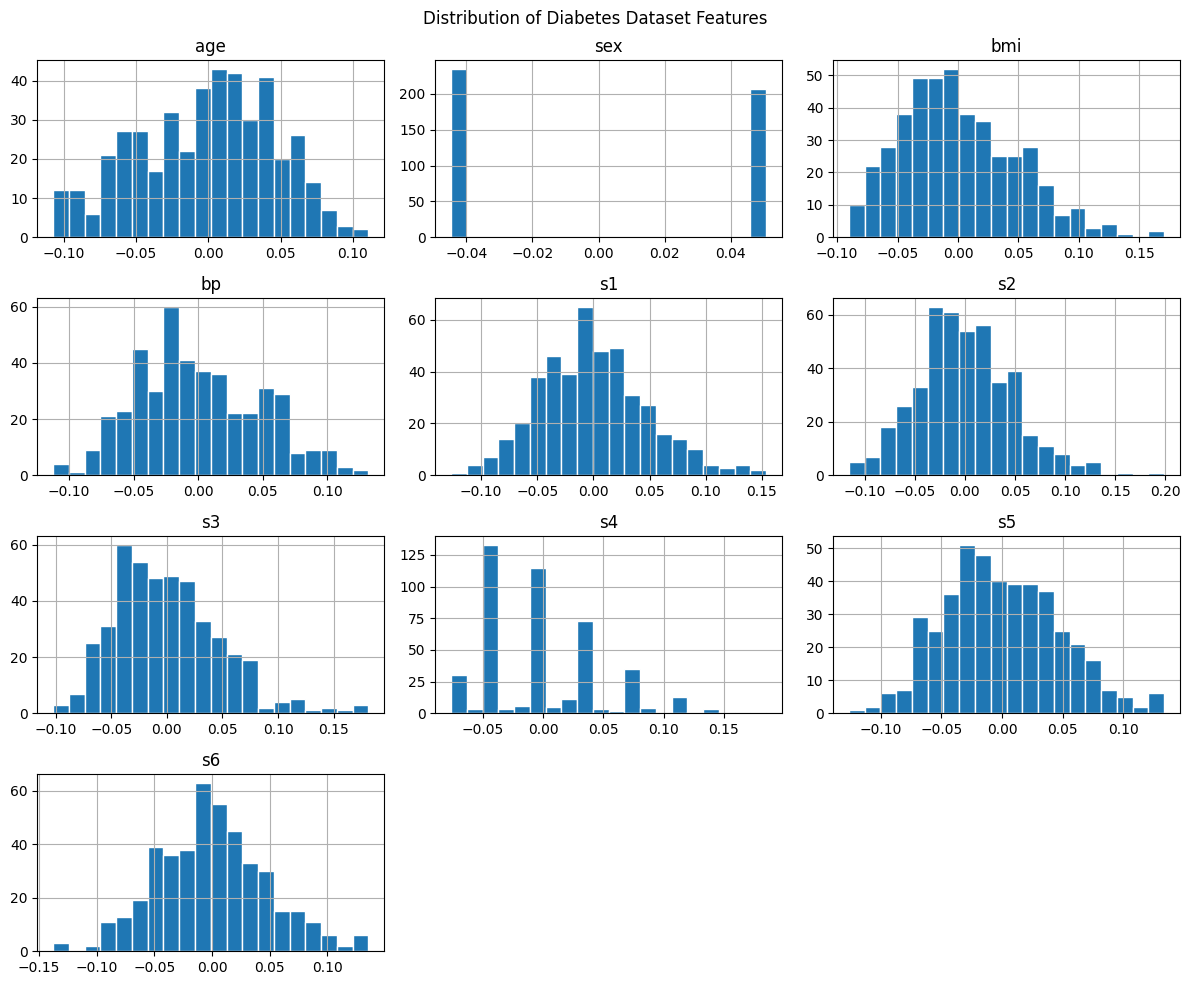

In [9]:
X.hist(figsize=(12, 10), bins=20, edgecolor="white")
plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

**DISTRIBUTING TARGET VARIABLE**

---



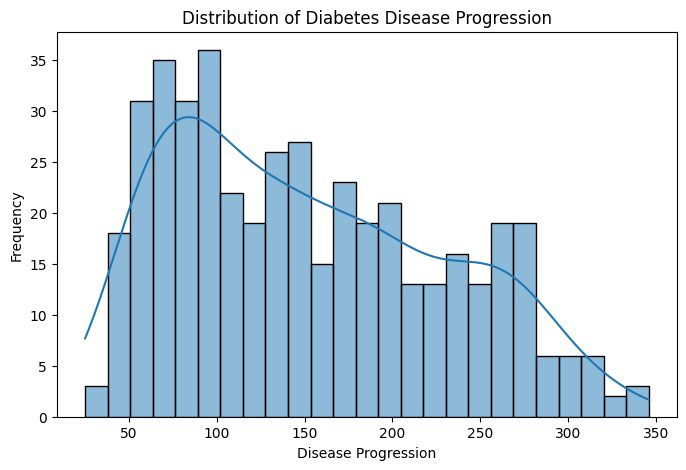

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(y, bins=25, kde=True)
plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Disease Progression")
plt.ylabel("Frequency")
plt.show()

**HEATMAP**

---



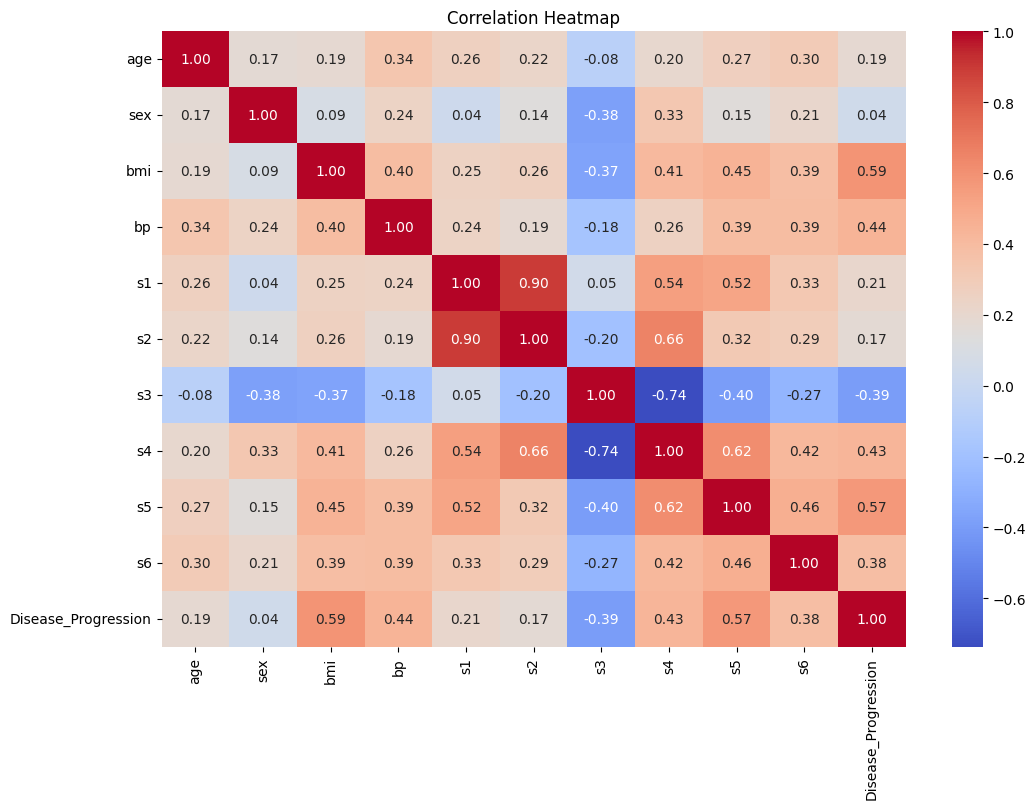

In [11]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**RELATIONSHIP BETWEEN FEATURES AND TARGET**

---



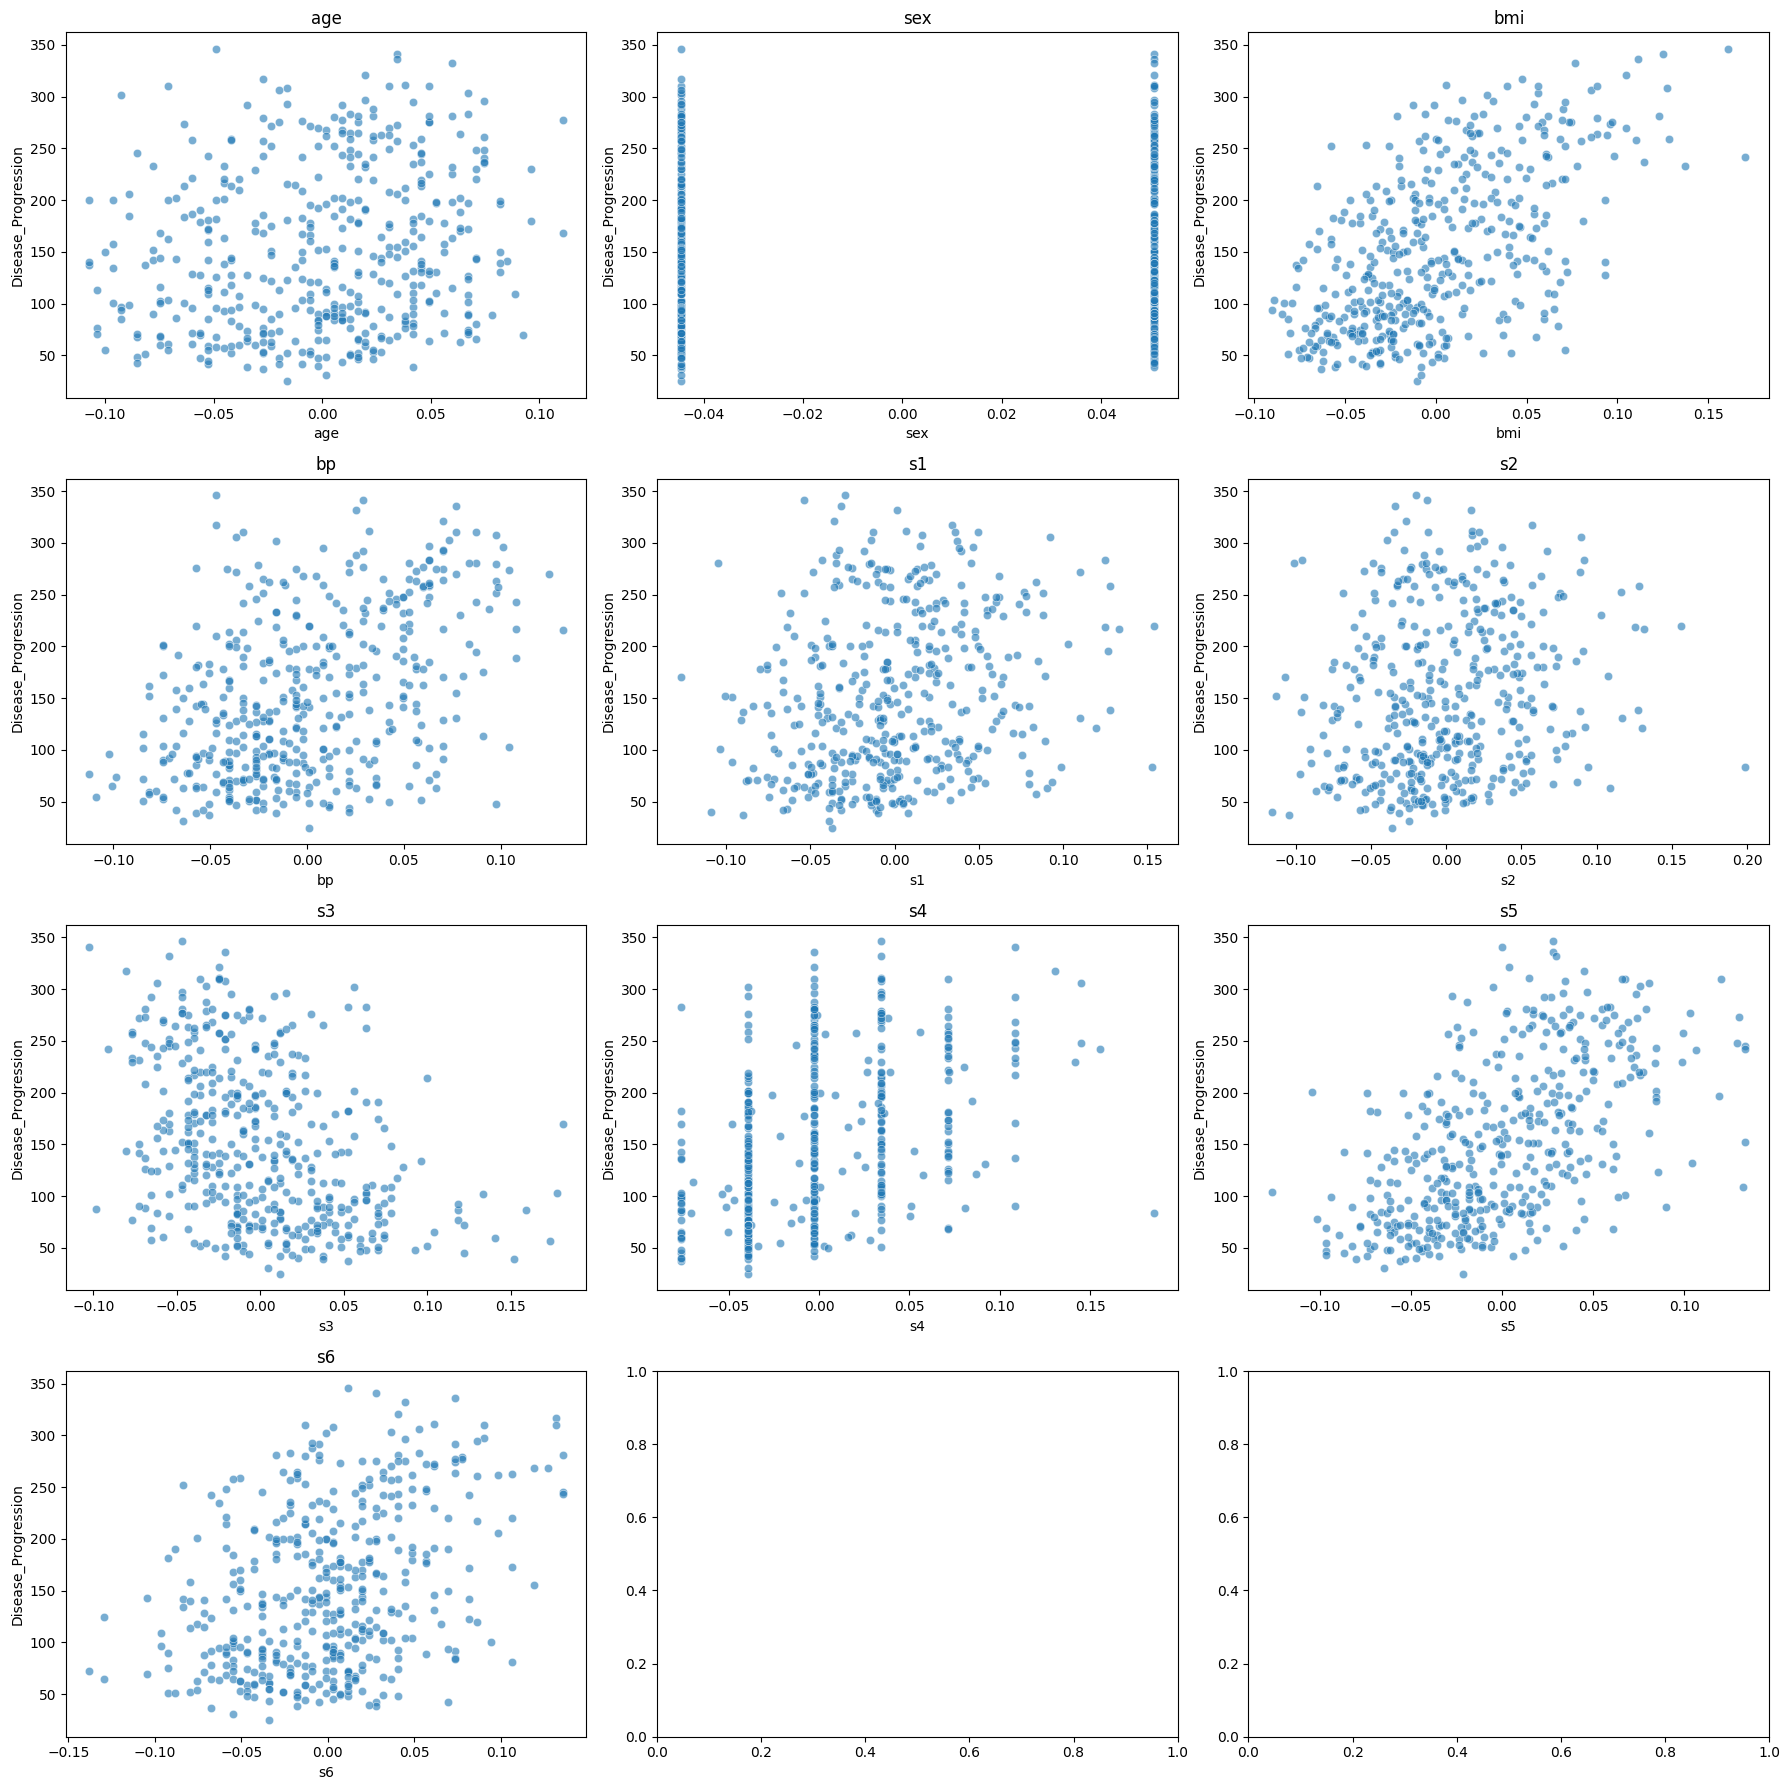

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(18, 18))

for i, feature in enumerate(X.columns):
   sns.scatterplot(data=df,x=feature,y="Disease_Progression",ax=axes[i // 3, i % 3],alpha=0.6)
   axes[i // 3, i % 3].set_title(feature)

plt.tight_layout()
plt.show()

# **BUILDING ANN MODEL**

---
**IMPORTING TENSORFLOW  AND KERAS**

---




In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

In [14]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

**COMPILING MODEL**

---



In [15]:
model.compile(optimizer=Adam(learning_rate=0.001),loss='mse',metrics=['mae'])

**TRAIN THE MODEL**

---



In [16]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - loss: 31465.6953 - mae: 158.2830 - val_loss: 22265.3555 - val_mae: 133.1945
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31235.6914 - mae: 157.5604 - val_loss: 22060.6309 - val_mae: 132.4293
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30961.3613 - mae: 156.6882 - val_loss: 21799.9707 - val_mae: 131.4430
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30613.1211 - mae: 155.5262 - val_loss: 21445.6523 - val_mae: 130.0991
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30126.7129 - mae: 153.9261 - val_loss: 20973.0078 - val_mae: 128.2805
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 29471.6172 - mae: 151.8040 - val_loss: 20368.4199 - val_mae: 125.9386
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 28628.1426 - mae: 149.0161 - val_loss: 19612.9434 - val_mae: 122.9863
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 27514.7676 - mae: 145.3727 - val_loss

**PLOTTING TRAINING AND VALIDATION LOSS**

---



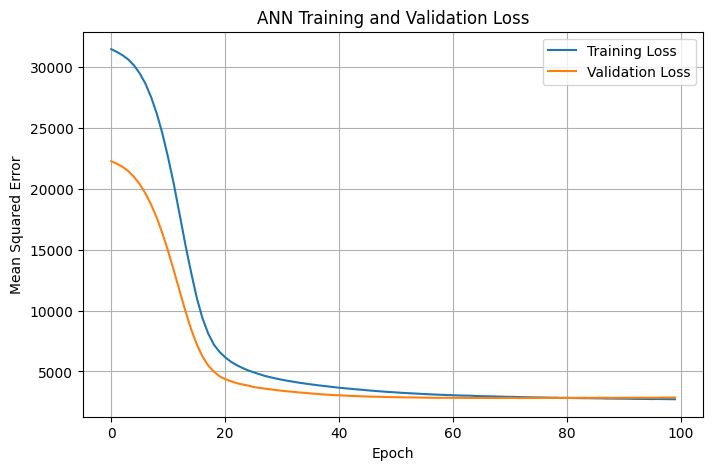

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()

**EVALUATING THE MODEL**

---
MAKE PREDICTIONS


In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = model.predict(X_test_scaled).flatten()

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step


In [21]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:",mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

MSE: 2960.8560969081245
RMSE: 54.4137491532069
MAE: 43.4651228658269
R2 Score: 0.4411530213838972


**COMPARING ACTUAL AND PREDICTED VALUES**

---



In [23]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
0,219.0,170.216278
1,70.0,190.261673
2,202.0,153.833069
3,230.0,317.126099
4,111.0,98.953270
5,84.0,118.380028
6,242.0,257.658508
7,272.0,179.398865
8,94.0,97.847351
9,96.0,69.292038


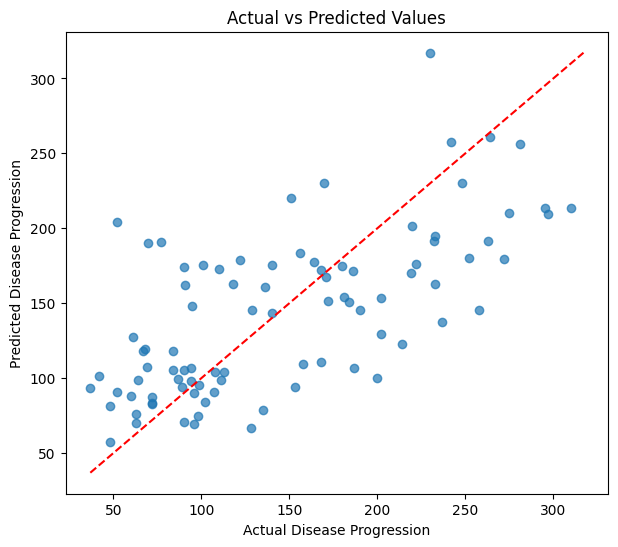

In [24]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], 'r--')

plt.xlabel('Actual Disease Progression')
plt.ylabel('Predicted Disease Progression')
plt.title('Actual vs Predicted Values')
plt.show()

**IMPROVING THE MODEL**

---



In [25]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

model_improved = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])

model_improved.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history_improved = model_improved.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - loss: 31533.7441 - mae: 158.6617 - val_loss: 22437.8848 - val_mae: 133.9068
Epoch 2/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 31423.6387 - mae: 158.3181 - val_loss: 22344.2227 - val_mae: 133.5572
Epoch 3/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 31280.6777 - mae: 157.8620 - val_loss: 22202.6797 - val_mae: 133.0341
Epoch 4/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 31062.2871 - mae: 157.1589 - val_loss: 21973.7324 - val_mae: 132.1729
Epoch 5/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 30716.2910 - mae: 156.0469 - val_loss: 21614.4023 - val_mae: 130.8210
Epoch 6/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 30154.5469 - mae: 154.2238 - val_loss: 21032.5391 - val_mae: 128.6358
Epoch 7/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 29227.6211 - mae: 151.2868 - val_loss: 20164.2520 - val_mae: 125.3526
Epoch 8/200
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 27858.1953 - mae: 146.8513 - val_los

**EVALUATING THE IMPROVED MODEL**

---



In [26]:
y_pred_improved = model_improved.predict(X_test_scaled).flatten()

results = pd.DataFrame({
    'Model': ['Original ANN', 'Improved ANN'],
    'MSE': [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, y_pred_improved)
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, y_pred_improved)
    ],
    'R2 Score': [
        r2_score(y_test, y_pred),
        r2_score(y_test, y_pred_improved)
    ]
})

print(results.round(4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 195ms/step
          Model        MSE      MAE  R2 Score
0  Original ANN  2960.8561  43.4651    0.4412
1  Improved ANN  3159.4463  44.5867    0.4037


In [27]:
model_v3 = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])

model_v3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

history_v3 = model_v3.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=15,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - loss: 31571.0430 - mae: 158.8027 - val_loss: 22513.0625 - val_mae: 134.1973
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 31494.7207 - mae: 158.5824 - val_loss: 22458.9902 - val_mae: 134.0126
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 31419.1250 - mae: 158.3667 - val_loss: 22406.7754 - val_mae: 133.8329
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 31343.3906 - mae: 158.1515 - val_loss: 22354.3418 - val_mae: 133.6518
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31267.4180 - mae: 157.9325 - val_loss: 22300.2695 - val_mae: 133.4648
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31188.6699 - mae: 157.7056 - val_loss: 22245.7383 - val_mae: 133.2766
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31106.4746 - mae: 157.4708 - val_loss: 22189.7676 - val_mae: 133.0848
Epoch 8/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 31020.5820 - mae: 157.2268 - val_

In [33]:
y_pred_v3 = model_v3(X_test_scaled, training=False).numpy().ravel()

mse_v3 = mean_squared_error(y_test, y_pred_v3)
rmse_v3 = np.sqrt(mse_v3)
mae_v3 = mean_absolute_error(y_test, y_pred_v3)
r2_v3 = r2_score(y_test, y_pred_v3)

print("ANN Model V3")
print("MSE:", round(mse_v3, 2))
print("RMSE:", round(rmse_v3, 2))
print("MAE:", round(mae_v3, 2))
print("R2 Score:", round(r2_v3, 4))

ANN Model V3
MSE: 4864.87
RMSE: 69.75
MAE: 53.85
R2 Score: 0.0818


**REPORT**

---

### Model Improvement and Comparison

Two ANN architectures were evaluated for predicting diabetes disease progression. The original model used hidden layers containing 32 and 16 neurons, with ReLU activation and the Adam optimizer. The improved model used 64, 32, and 16 neurons, dropout regularization, a lower learning rate, early stopping, and target standardization.

The original model achieved an MSE of 2960.86, MAE of 43.47, and R² score of 0.4412. The improved model achieved an MSE of 3159.45, MAE of 44.59, and R² score of 0.4037.When I tried to improve for the second time then it got MSE of 4864.87, MAE of 53.85, and R² score of 0.0818

The original model performed better on the test set. The experiments demonstrate that increasing network complexity and applying regularization do not necessarily improve predictive performance. Further experiments with simpler architectures and training parameters can help identify a more suitable model.

**Best model so far:** Original ANN.
